In [2]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

print("data folder:", DATA.resolve(), "| exists:", DATA.exists())

data folder: C:\Users\M.A Computer\Documents\king-county-flood-house-price\data | exists: True


In [1]:
!pip install geopandas


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd, geopandas as gpd

fp= gpd.read_file(DATA / "FEMA_100_year_floodplain.shp")

print(fp.crs)
print(fp.shape)

PROJCS["NAD83(HARN) / Washington North (ftUS)",GEOGCS["NAD83(HARN)",DATUM["NAD83_High_Accuracy_Reference_Network",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6152"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",47],PARAMETER["central_meridian",-120.833333333333],PARAMETER["standard_parallel_1",47.5],PARAMETER["standard_parallel_2",48.7333333333333],PARAMETER["false_easting",1640416.66666667],PARAMETER["false_northing",0],UNIT["US survey foot",0.304800609601219,AUTHORITY["EPSG","9003"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
(2319, 8)


In [3]:
print(fp["FLD_ZONE"].value_counts())

FLD_ZONE
AE    1823
VE     278
A      109
AH      78
AO      31
Name: count, dtype: int64


In [4]:
fp.columns

Index(['FLD_ZONE', 'FLOODWAY', 'STATIC_BFE', 'V_DATUM', 'DEPTH_', 'LEN_UNIT',
       'SOURCE_CIT', 'geometry'],
      dtype='object')

In [4]:
import pandas as pd

sales = pd.read_csv(DATA / "EXTR_RPSale.csv", dtype=str, encoding="latin-1")
res   = pd.read_csv(DATA / "EXTR_ResBldg.csv", dtype=str, encoding="latin-1")
parc  = pd.read_csv(DATA / "EXTR_Parcel.csv", dtype=str, encoding="latin-1")

In [6]:
for name, d in [("sales", sales), ("res", res), ("parcel", parc)]:
    print(name, d.shape)
    print(list(d.columns), "\n")

sales (2449506, 24)
['ExciseTaxNbr', 'Major', 'Minor', 'DocumentDate', 'SalePrice', 'RecordingNbr', 'Volume', 'Page', 'PlatNbr', 'PlatType', 'PlatLot', 'PlatBlock', 'SellerName', 'BuyerName', 'PropertyType', 'PrincipalUse', 'SaleInstrument', 'AFForestLand', 'AFCurrentUseLand', 'AFNonProfitUse', 'AFHistoricProperty', 'SaleReason', 'PropertyClass', 'SaleWarning'] 

res (533748, 50)
['Major', 'Minor', 'BldgNbr', 'NbrLivingUnits', 'Address', 'BuildingNumber', 'Fraction', 'DirectionPrefix', 'StreetName', 'StreetType', 'DirectionSuffix', 'ZipCode', 'Stories', 'BldgGrade', 'BldgGradeVar', 'SqFt1stFloor', 'SqFtHalfFloor', 'SqFt2ndFloor', 'SqFtUpperFloor', 'SqFtUnfinFull', 'SqFtUnfinHalf', 'SqFtTotLiving', 'SqFtTotBasement', 'SqFtFinBasement', 'FinBasementGrade', 'SqFtGarageBasement', 'SqFtGarageAttached', 'DaylightBasement', 'SqFtOpenPorch', 'SqFtEnclosedPorch', 'SqFtDeck', 'HeatSystem', 'HeatSource', 'BrickStone', 'ViewUtilization', 'Bedrooms', 'BathHalfCount', 'Bath3qtrCount', 'BathFullCount

In [7]:
sales["DocumentDate"] = pd.to_datetime(sales["DocumentDate"], errors="coerce")
sales["SalePrice"] = pd.to_numeric(sales["SalePrice"], errors="coerce")
sales["PIN"] = sales["Major"].str.zfill(6) + sales["Minor"].str.zfill(4)

In [8]:
print(sales["SalePrice"].describe())

count    2.449506e+06
mean     6.579968e+05
std      6.122297e+06
min     -6.000000e+02
25%      0.000000e+00
50%      1.650000e+05
75%      4.285000e+05
max      7.398850e+08
Name: SalePrice, dtype: float64


In [9]:
sales["DocumentDate"].head()

0   2022-05-24
1   2016-09-06
2   2016-06-14
3   2008-07-23
4   2012-03-28
Name: DocumentDate, dtype: datetime64[ns]

In [10]:
s= sales[(sales["DocumentDate"]>= "2020-01-01") & (sales["SalePrice"] > 100000)]
print(len(s))
print(s["SalePrice"].describe(percentiles=[.01, .05, .5, .95, .99]))

241434
count    2.414340e+05
mean     1.514852e+06
std      7.809207e+06
min      1.000330e+05
1%       1.750000e+05
5%       2.995000e+05
50%      7.860000e+05
95%      2.900000e+06
99%      1.250000e+07
max      7.298000e+08
Name: SalePrice, dtype: float64


In [11]:
for c in ["PropertyType", "SaleReason", "SaleInstrument", "SaleWarning"]:
    print(c)
    print(s[c].value_counts().head(15), "\n")

PropertyType
PropertyType
11    139869
14     36349
3      31310
10     10052
2       8299
1       4455
91      3763
12      1735
59      1627
13      1320
4        510
50       275
0        222
99       189
53       144
Name: count, dtype: int64 

SaleReason
SaleReason
1     230365
18      8331
8       1137
4        698
5        466
19       144
14        79
12        53
10        43
11        39
16        24
13        23
9         10
17         8
0          7
Name: count, dtype: int64 

SaleInstrument
SaleInstrument
2     185422
3      40751
27      5259
15      3651
22      3326
4        866
18       791
26       610
24       391
10       155
21       104
23        65
5         15
19         9
20         6
Name: count, dtype: int64 

SaleWarning
SaleWarning
         185321
15         7494
26         5459
45         5448
12         2697
10         2441
15 46      1515
15 51      1250
15 26      1190
49         1098
40         1022
45 56      1004
10 15       984
48          963
41   

In [12]:
df = s.copy()
for c in ["PropertyType", "PrincipalUse", "PropertyClass", "SaleReason", "SaleInstrument", "SaleWarning"]:
    df[c] = df[c].fillna("").str.strip()
print("start:", len(df))

df = df[df["PropertyType"] == "11"]       # LUType 1: single-family household
print("after property type:", len(df))

df = df[df["PrincipalUse"] == "6"]        # LUType 2: residential
print("after principal use:", len(df))

df = df[df["PropertyClass"] == "8"]       # LUType 4: residential, improved property
print("after property class:", len(df))

df = df[df["SaleReason"] == "1"]          # LUType 5: none (normal sale)
print("after sale reason:", len(df))

df = df[df["SaleInstrument"].isin(["2", "3", "4"])]   # LUType 6: warranty deeds
print("after deed type:", len(df))

bad = {"5","7","8","9","10","11","12","13","14","15","18","22","23","26","31","32",
       "33","36","37","38","40","41","45","46","49","50","51","52","53","57","59",
       "60","61","62","63","64","66","67","68"}
df = df[df["SaleWarning"].apply(lambda w: set(w.split()).isdisjoint(bad))]
print("after warnings:", len(df))

start: 241434
after property type: 139869
after principal use: 137099
after property class: 132725
after sale reason: 132374
after deed type: 127896
after warnings: 109811


In [13]:
print(df["SalePrice"].describe(percentiles=[.01, .05, .5, .95, .99]))

count    1.098110e+05
mean     1.148518e+06
std      8.658887e+05
min      1.147500e+05
1%       3.850000e+05
5%       4.750000e+05
50%      9.000000e+05
95%      2.525000e+06
99%      4.250000e+06
max      3.800000e+07
Name: SalePrice, dtype: float64


In [14]:
print(res.columns.tolist())
print(res.head(3).T)

['Major', 'Minor', 'BldgNbr', 'NbrLivingUnits', 'Address', 'BuildingNumber', 'Fraction', 'DirectionPrefix', 'StreetName', 'StreetType', 'DirectionSuffix', 'ZipCode', 'Stories', 'BldgGrade', 'BldgGradeVar', 'SqFt1stFloor', 'SqFtHalfFloor', 'SqFt2ndFloor', 'SqFtUpperFloor', 'SqFtUnfinFull', 'SqFtUnfinHalf', 'SqFtTotLiving', 'SqFtTotBasement', 'SqFtFinBasement', 'FinBasementGrade', 'SqFtGarageBasement', 'SqFtGarageAttached', 'DaylightBasement', 'SqFtOpenPorch', 'SqFtEnclosedPorch', 'SqFtDeck', 'HeatSystem', 'HeatSource', 'BrickStone', 'ViewUtilization', 'Bedrooms', 'BathHalfCount', 'Bath3qtrCount', 'BathFullCount', 'FpSingleStory', 'FpMultiStory', 'FpFreestanding', 'FpAdditional', 'YrBuilt', 'YrRenovated', 'PcntComplete', 'Obsolescence', 'PcntNetCondition', 'Condition', 'AddnlCost']
                                             0                           1  \
Major                                   002350                      002350   
Minor                                     0210       

In [15]:
# 1. Build PIN in the building file
res["PIN"] = res["Major"].str.zfill(6) + res["Minor"].str.zfill(4)

# 2. How many parcels have more than one building?
n_bldg = res.groupby("PIN")["BldgNbr"].count()
print((n_bldg > 1).sum(), "parcels with multiple buildings")

7419 parcels with multiple buildings


In [16]:
# 3. Keep parcels with exactly one building (no ambiguity about which house was sold)
single = n_bldg[n_bldg == 1].index
res1 = res[res["PIN"].isin(single)].copy()

# 4. Select feature columns
feat = ["PIN","NbrLivingUnits","Stories","BldgGrade","SqFtTotLiving","SqFt1stFloor",
        "SqFtTotBasement","SqFtFinBasement","SqFtGarageAttached","SqFtOpenPorch","SqFtDeck",
        "Bedrooms","BathHalfCount","Bath3qtrCount","BathFullCount",
        "YrBuilt","YrRenovated","Condition","ZipCode","ViewUtilization","DaylightBasement"]
res1 = res1[feat]

In [17]:
num = [c for c in feat if c not in ["PIN","ZipCode","ViewUtilization","DaylightBasement"]]
for c in num:
    res1[c] = pd.to_numeric(res1[c], errors="coerce")

In [18]:
# Merge
m = df.merge(res1, on="PIN", how="inner")
print("after merge:", len(m))

# a) duplicate sales
print("duplicates:", m.duplicated(subset=["PIN","DocumentDate","SalePrice"]).sum())

# b) house built after the sale
m["sale_year"] = m["DocumentDate"].dt.year
print("built after sale:", (m["YrBuilt"] > m["sale_year"]).sum())

# c) impossible values
print(m[["SqFtTotLiving","Bedrooms","YrBuilt"]].describe())
print("zero sqft:", (m["SqFtTotLiving"] == 0).sum(), " zero bedrooms:", (m["Bedrooms"] == 0).sum())

after merge: 108150
duplicates: 32
built after sale: 173
       SqFtTotLiving       Bedrooms        YrBuilt
count  108150.000000  108150.000000  108150.000000
mean     2232.477300       3.513925    1976.809219
std       983.949194       0.920569      31.215741
min       140.000000       0.000000    1900.000000
25%      1530.000000       3.000000    1955.000000
50%      2050.000000       3.000000    1979.000000
75%      2740.000000       4.000000    2004.000000
max     13540.000000      12.000000    2026.000000
zero sqft: 0  zero bedrooms: 21


In [19]:
# look at tiny houses first
print((m["SqFtTotLiving"] < 400).sum(), "rows under 400 sqft")
print(m.loc[m["SqFtTotLiving"] < 400, ["PIN","SalePrice","SqFtTotLiving","Bedrooms","YrBuilt"]].head(10))

16 rows under 400 sqft
              PIN  SalePrice  SqFtTotLiving  Bedrooms  YrBuilt
1484   4250900036     405000            320         1     1938
4988   4443800266     414000            360         0     1969
7561   2322029049     625000            300         1     1947
9025   7192800139     425000            370         0     1946
14876  2291400450     380000            320         1     1925
15078  2856101479     499950            370         0     1923
16514  4053200655     280000            140         1     1959
37348  0121029099     114750            300         0     1983
48769  1370804345     570000            380         1     1949
50601  6102400167     520000            350         1     1940


In [20]:
n0 = len(m)

m = m.drop_duplicates(subset=["PIN","DocumentDate","SalePrice"])
print("after duplicates:", len(m), f"(-{n0-len(m)})")

n1 = len(m)
m = m[m["YrBuilt"] <= m["sale_year"]]
print("after built-after-sale:", len(m), f"(-{n1-len(m)})")

n2 = len(m)
m = m[m["Bedrooms"] > 0]
print("after zero bedrooms:", len(m), f"(-{n2-len(m)})")

m = m.reset_index(drop=True)
print("final:", len(m))

after duplicates: 108118 (-32)
after built-after-sale: 107945 (-173)
after zero bedrooms: 107924 (-21)
final: 107924


In [21]:
parc["PIN"] = parc["Major"].str.zfill(6) + parc["Minor"].str.zfill(4)
print("duplicate PINs:", parc["PIN"].duplicated().sum())

keep = ["PIN","SqFtLot","WfntLocation","TrafficNoise","MtRainier","Olympics","Cascades",
        "Territorial","SeattleSkyline","PugetSound","LakeWashington","LakeSammamish",
        "SmallLakeRiverCreek","OtherView","HundredYrFloodPlain"]
pf = parc[keep].copy()

for c in keep[1:]:
    if c != "HundredYrFloodPlain":
        pf[c] = pd.to_numeric(pf[c], errors="coerce")

m = m.merge(pf, on="PIN", how="left")
print(len(m))
print(m["HundredYrFloodPlain"].value_counts(dropna=False))

duplicate PINs: 0
107924
HundredYrFloodPlain
N    107924
Name: count, dtype: int64


In [22]:
m = m.drop(columns=["HundredYrFloodPlain"])

In [23]:
cols = ["SqFtLot","WfntLocation","TrafficNoise","MtRainier","Olympics","Cascades",
        "Territorial","SeattleSkyline","PugetSound","LakeWashington","LakeSammamish",
        "SmallLakeRiverCreek","OtherView"]
print(m[cols].nunique())
print(m["SqFtLot"].describe())

SqFtLot                22391
WfntLocation               9
TrafficNoise               4
MtRainier                  4
Olympics                   4
Cascades                   4
Territorial                4
SeattleSkyline             4
PugetSound                 5
LakeWashington             5
LakeSammamish              5
SmallLakeRiverCreek        4
OtherView                  4
dtype: int64
count    1.079240e+05
mean     1.487795e+04
std      4.156126e+04
min      3.780000e+02
25%      4.980000e+03
50%      7.500000e+03
75%      1.052500e+04
max      1.759388e+06
Name: SqFtLot, dtype: float64


In [6]:
parcels = gpd.read_file(DATA / "King_County_Parcels.shp")
print(parcels.columns.tolist())
print(parcels.crs)
print(len(parcels))
print("duplicate PINs:", parcels["PIN"].duplicated().sum())
print(parcels.geometry.type.value_counts())

['MAJOR', 'MINOR', 'PIN', 'geometry']
PROJCS["NAD83(HARN) / Washington North (ftUS)",GEOGCS["NAD83(HARN)",DATUM["NAD83_High_Accuracy_Reference_Network",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6152"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",47],PARAMETER["central_meridian",-120.833333333333],PARAMETER["standard_parallel_1",47.5],PARAMETER["standard_parallel_2",48.7333333333333],PARAMETER["false_easting",1640416.66666667],PARAMETER["false_northing",0],UNIT["US survey foot",0.304800609601219,AUTHORITY["EPSG","9003"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
639343
duplicate PINs: 2560
Polygon         634619
MultiPolygon      4724
Name: count, dtype: int64


In [25]:
print(parcels.shape)

(639343, 4)


In [26]:
import geopandas as gpd

# 1. Keep only parcels that appear in your sales, one shape per PIN
parcels["PIN"] = parcels["PIN"].str.strip()
sub = parcels[parcels["PIN"].isin(m["PIN"])][["PIN", "geometry"]]
print("parcel rows:", len(sub), "| duplicate PINs:", sub["PIN"].duplicated().sum())

sub = sub.dissolve(by="PIN").reset_index()
sub["geometry"] = sub.geometry.make_valid()
sub["parcel_area"] = sub.geometry.area

missing = set(m["PIN"]) - set(sub["PIN"])
print("sales PINs with no parcel shape:", len(missing))

parcel rows: 100735 | duplicate PINs: 0
sales PINs with no parcel shape: 0


In [27]:
# 2. drop open water, match the CRS
print(fp.crs)
print(fp["FLD_ZONE"].value_counts())

PROJCS["NAD83(HARN) / Washington North (ftUS)",GEOGCS["NAD83(HARN)",DATUM["NAD83_High_Accuracy_Reference_Network",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6152"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",47],PARAMETER["central_meridian",-120.833333333333],PARAMETER["standard_parallel_1",47.5],PARAMETER["standard_parallel_2",48.7333333333333],PARAMETER["false_easting",1640416.66666667],PARAMETER["false_northing",0],UNIT["US survey foot",0.304800609601219,AUTHORITY["EPSG","9003"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
FLD_ZONE
AE    1823
VE     278
A      109
AH      78
AO      31
Name: count, dtype: int64


In [28]:
flood= fp.copy()

In [29]:
flood = flood[flood["FLD_ZONE"] != "OPEN WATER"].to_crs(sub.crs)
flood["geometry"] = flood.geometry.make_valid()
flood_u = flood.dissolve()                 # one combined floodplain shape

In [31]:
# 3. Intersect and measure the overlap
inter = gpd.overlay(sub[["PIN", "geometry"]], flood_u[["geometry"]], how="intersection")

In [32]:
inter["flood_area"] = inter.geometry.area

In [33]:
fa = inter.groupby("PIN")["flood_area"].sum()

In [34]:
sub["flood_share"] = (sub["PIN"].map(fa).fillna(0) / sub["parcel_area"]).clip(upper=1)
sub["in_floodplain_any"] = (sub["flood_share"] > 0).astype(int)

In [35]:
# 4. Attach to your sales table
m2 = m.merge(sub[["PIN", "parcel_area", "flood_share", "in_floodplain_any"]], on="PIN", how="left")
print(len(m), len(m2))

107924 107924


In [36]:
print(m2["in_floodplain_any"].value_counts(dropna=False))
print(m2.loc[m2["flood_share"] > 0, "flood_share"].describe())

# Does the parcel shape match the assessor's lot size?
print((m2["parcel_area"] / m2["SqFtLot"]).describe())

# Raw price comparison (not a conclusion yet)
print(m2.groupby("in_floodplain_any")["SalePrice"].median())

in_floodplain_any
0    106054
1      1870
Name: count, dtype: int64
count    1.870000e+03
mean     5.256499e-01
std      3.855282e-01
min      1.010927e-07
25%      1.494728e-01
50%      4.532950e-01
75%      1.000000e+00
max      1.000000e+00
Name: flood_share, dtype: float64
count    107924.000000
mean          1.001748
std           0.080408
min           0.098640
25%           0.997297
50%           1.000009
75%           1.003637
max          24.321229
dtype: float64
in_floodplain_any
0    900000.0
1    976600.0
Name: SalePrice, dtype: float64


In [37]:
f = m2["flood_share"]
for t in [0, 0.01, 0.05, 0.10, 0.25, 0.5, 0.99]:
    print(f">{t:.2f}:", (f > t).sum())

>0.00: 1870
>0.01: 1809
>0.05: 1683
>0.10: 1538
>0.25: 1190
>0.50: 892
>0.99: 553


In [38]:
r = m2["parcel_area"] / m2["SqFtLot"]
print(((r < 0.9) | (r > 1.1)).sum())
print(m2.loc[(r < 0.9) | (r > 1.1), ["PIN","SqFtLot","parcel_area","flood_share"]].head(10))

2101
            PIN  SqFtLot   parcel_area  flood_share
36   7214700570    50094  41656.689707          0.0
57   0868000790     8393   9382.804846          0.0
165  1974000020     7200   8851.875884          0.0
192  4006000080     4173   4731.244975          0.0
268  3298610130    25300  14318.324587          0.0
309  8965500950     9717   8688.890212          0.0
374  1796351050     5704   7365.981551          0.0
431  7010700055     3068   2667.420543          0.0
457  1274500470    12707  10602.371936          0.0
577  2621750672    10333   8910.612567          0.0


In [39]:
r = m2["parcel_area"] / m2["SqFtLot"]
bad = (r < 0.9) | (r > 1.1)
print("mismatched:", bad.sum())
print("mismatched AND flood_share > 0:", (bad & (m2["flood_share"] > 0)).sum())

mismatched: 2101
mismatched AND flood_share > 0: 72


In [40]:
bad = ((m2["parcel_area"] / m2["SqFtLot"]) < 0.9) | ((m2["parcel_area"] / m2["SqFtLot"]) > 1.1)
m2["area_mismatch"] = bad.astype(int)
m2["flood_5pct"]  = (m2["flood_share"] > 0.05).astype(int)
m2["flood_10pct"] = (m2["flood_share"] > 0.10).astype(int)

In [41]:
import numpy as np

d = m2.copy()

# 1. Log transforms
d["log_price"]  = np.log(d["SalePrice"])
d["log_living"] = np.log(d["SqFtTotLiving"])
d["log_lot"]    = np.log(d["SqFtLot"])

# 2. Age of the house at the time of sale
d["age"] = d["sale_year"] - d["YrBuilt"]

# 3. One bathroom number
d["baths"] = d["BathFullCount"] + 0.75 * d["Bath3qtrCount"] + 0.5 * d["BathHalfCount"]

# 4. Sale month
d["sale_ym"] = d["DocumentDate"].dt.to_period("M").astype(str)

# 5. Check missing values
cols = ["log_price","log_living","log_lot","age","baths","Bedrooms","BldgGrade","Condition",
        "WfntLocation","TrafficNoise","ZipCode","flood_share"]
print(d[cols].isna().sum())
print(d[["log_price","log_living","log_lot","age","baths"]].describe())

log_price           0
log_living          0
log_lot             0
age                 0
baths               0
Bedrooms            0
BldgGrade           0
Condition           0
WfntLocation        0
TrafficNoise        0
ZipCode         14654
flood_share         0
dtype: int64
           log_price     log_living        log_lot            age  \
count  107924.000000  107924.000000  107924.000000  107924.000000   
mean       13.794577       7.620688       8.931494      45.934046   
std         0.522161       0.422881       0.964991      31.264231   
min        11.736069       4.941642       5.934894       0.000000   
25%        13.415033       7.333023       8.513185      19.000000   
50%        13.710150       7.625595       8.922658      43.000000   
75%        14.116356       7.915713       9.261509      67.000000   
max        17.281246       9.513404      14.380477     126.000000   

               baths  
count  107924.000000  
mean        2.328164  
std         0.789853  
min      

In [44]:
# 1. Are the missing zips spread evenly across flood and non-flood homes?
d["zip_missing"] = d["ZipCode"].isna().astype(int)
print(d.groupby("in_floodplain_any")["zip_missing"].mean())

# 2. Is zip blank, or just not stored in that column? Look at the Address text.
print(res[["Address","ZipCode"]][res["ZipCode"].isna() | (res["ZipCode"].str.strip() == "")].head(10))

# 3. Bathrooms
print((d["baths"] == 0).sum(), "houses with zero baths")

in_floodplain_any
0    0.137091
1    0.061497
Name: zip_missing, dtype: float64
                        Address ZipCode
63          9204  SE 42ND ST        NaN
84          5311   33RD ST SE       NaN
105  8034   FAUNTLEROY WAY SW       NaN
111  8312   FAUNTLEROY WAY SW       NaN
112  8312   FAUNTLEROY WAY SW       NaN
117        8314   46TH AVE SW       NaN
132  8304   FAUNTLEROY WAY SW       NaN
138         4439  SW ROSE ST        NaN
182  8233   CALIFORNIA AVE SW       NaN
254         14411   44TH LN S       NaN
6 houses with zero baths


In [45]:
# 1. Parcel centre points (coordinates in feet)
sub["cx"] = sub.geometry.centroid.x
sub["cy"] = sub.geometry.centroid.y

# 2. Attach them to the model table
d = d.merge(sub[["PIN", "cx", "cy"]], on="PIN", how="left")

# 3. Grid squares: 1 mile = 5,280 ft, and half a mile = 2,640 ft
d["cell_1mi"]  = (d["cx"] // 5280).astype(int).astype(str) + "_" + (d["cy"] // 5280).astype(int).astype(str)
d["cell_half"] = (d["cx"] // 2640).astype(int).astype(str) + "_" + (d["cy"] // 2640).astype(int).astype(str)

# 4. Checks
print(len(d))
print(d[["cx", "cy"]].isna().sum())
print("1-mile cells:", d["cell_1mi"].nunique(), "| half-mile cells:", d["cell_half"].nunique())
print("cells containing a flood-zone home:", d.loc[d["flood_5pct"] == 1, "cell_1mi"].nunique())

107924
cx    0
cy    0
dtype: int64
1-mile cells: 978 | half-mile cells: 3019
cells containing a flood-zone home: 274


In [46]:
import pandas as pd
import statsmodels.formula.api as smf

d["sale_q"] = d["DocumentDate"].dt.to_period("Q").astype(str)

formula = ("log_price ~ flood_share + log_living + log_lot + age + I(age**2) + baths + Bedrooms"
           " + BldgGrade + C(Condition) + C(WfntLocation) + C(TrafficNoise)"
           " + C(MtRainier) + C(Olympics) + C(Cascades) + C(Territorial) + C(SeattleSkyline)"
           " + C(PugetSound) + C(LakeWashington) + C(LakeSammamish) + C(SmallLakeRiverCreek) + C(OtherView)"
           " + C(sale_q) + C(cell_1mi)")

groups = pd.factorize(d["cell_1mi"])[0]

In [47]:
model = smf.ols(formula, data=d).fit(cov_type="cluster", cov_kwds={"groups": groups})

In [48]:
print("rows used:", int(model.nobs), "| R-squared:", round(model.rsquared, 3))
print("flood_share coefficient:", model.params["flood_share"])
print("95% CI:", model.conf_int().loc["flood_share"].values)
print("p-value:", model.pvalues["flood_share"])

rows used: 107924 | R-squared: 0.93
flood_share coefficient: -0.05224403419985571
95% CI: [-0.07822643 -0.02626164]
p-value: 8.114498381307179e-05


In [49]:
formula_base = ("log_price ~ log_living + log_lot + age + I(age**2) + baths + Bedrooms"
                " + BldgGrade + C(Condition) + C(WfntLocation) + C(TrafficNoise)"
                " + C(MtRainier) + C(Olympics) + C(Cascades) + C(Territorial) + C(SeattleSkyline)"
                " + C(PugetSound) + C(LakeWashington) + C(LakeSammamish) + C(SmallLakeRiverCreek) + C(OtherView)"
                " + C(sale_q)")

def run(label, data, flood_var="flood_share", cell="cell_1mi"):
    f = f"{formula_base} + {flood_var} + C({cell})"
    g = pd.factorize(data[cell])[0]
    mod = smf.ols(f, data=data).fit(cov_type="cluster", cov_kwds={"groups": g})
    lo, hi = mod.conf_int().loc[flood_var]
    print(f"{label:<28} coef={mod.params[flood_var]:+.4f}  CI=[{lo:+.4f}, {hi:+.4f}]  p={mod.pvalues[flood_var]:.4f}  n={int(mod.nobs)}")

In [51]:
run("1. flood_share (baseline)", d)

1. flood_share (baseline)    coef=-0.0522  CI=[-0.0782, -0.0263]  p=0.0001  n=107924


In [52]:
run("2. flag: share > 5%", d, flood_var="flood_5pct")

2. flag: share > 5%          coef=-0.0483  CI=[-0.0699, -0.0266]  p=0.0000  n=107924


In [53]:
run("3. flag: share > 10%", d, flood_var="flood_10pct")

3. flag: share > 10%         coef=-0.0463  CI=[-0.0661, -0.0265]  p=0.0000  n=107924


In [54]:
run("4. without area mismatches", d[d["area_mismatch"] == 0])

4. without area mismatches   coef=-0.0524  CI=[-0.0792, -0.0256]  p=0.0001  n=105823


In [55]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

d["t"] = d["DocumentDate"].dt.year + d["DocumentDate"].dt.dayofyear / 365

base = ["log_living","log_lot","age","baths","Bedrooms","BldgGrade","Condition",
        "WfntLocation","TrafficNoise","MtRainier","Olympics","Cascades","Territorial",
        "SeattleSkyline","PugetSound","LakeWashington","LakeSammamish",
        "SmallLakeRiverCreek","OtherView","cx","cy","t"]
with_flood = base + ["flood_share"]

y = d["log_price"]

In [56]:
#split data into traning, testing 
tr, te = train_test_split(d.index, test_size=0.2, random_state=42)

def score(name, model, cols):
    model.fit(d.loc[tr, cols], y[tr])
    p = model.predict(d.loc[te, cols])
    rmse = np.sqrt(mean_squared_error(y[te], p))
    r2 = r2_score(y[te], p)
    mape = np.median(np.abs(np.exp(p) - np.exp(y[te])) / np.exp(y[te]))
    print(f"{name:<32} RMSE(log)={rmse:.4f}  R2={r2:.3f}  median error={mape:.1%}")
    return model

In [57]:
score("Linear, no flood", LinearRegression(), base)
score("Linear, with flood", LinearRegression(), with_flood)

Linear, no flood                 RMSE(log)=0.2340  R2=0.804  median error=14.6%
Linear, with flood               RMSE(log)=0.2340  R2=0.804  median error=14.6%


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [58]:
rf0 = score("Random Forest, no flood", RandomForestRegressor(200, min_samples_leaf=3, n_jobs=-1, random_state=42), base)
rf1 = score("Random Forest, with flood", RandomForestRegressor(200, min_samples_leaf=3, n_jobs=-1, random_state=42), with_flood)

Random Forest, no flood          RMSE(log)=0.1350  R2=0.935  median error=7.1%
Random Forest, with flood        RMSE(log)=0.1351  R2=0.935  median error=7.1%


In [62]:
from sklearn.inspection import permutation_importance

sample = te[:5000]
pi = permutation_importance(rf1, d.loc[sample, with_flood], y[sample],
                            n_repeats=5, random_state=42, n_jobs=1, scoring="r2")
imp = pd.Series(pi.importances_mean, index=with_flood).sort_values(ascending=False)
print(imp.round(4))

cy                     0.6466
log_living             0.2747
BldgGrade              0.1934
t                      0.0927
cx                     0.0810
log_lot                0.0444
age                    0.0108
WfntLocation           0.0094
Condition              0.0056
baths                  0.0031
PugetSound             0.0016
LakeWashington         0.0013
TrafficNoise           0.0011
Territorial            0.0008
LakeSammamish          0.0004
Bedrooms               0.0003
Olympics               0.0002
flood_share            0.0001
SeattleSkyline         0.0001
Cascades               0.0000
SmallLakeRiverCreek    0.0000
OtherView              0.0000
MtRainier             -0.0000
dtype: float64


In [63]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

Xv = sm.add_constant(d.loc[tr, base].sample(20000, random_state=42).astype(float))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=base).sort_values(ascending=False)
print(vif.round(2))

corr = d.loc[tr, base].corr().abs()
print(corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False).head(10))

log_living             4.88
baths                  3.15
Territorial            2.80
BldgGrade              2.74
PugetSound             2.08
WfntLocation           2.04
Bedrooms               2.03
age                    2.00
Olympics               1.98
SmallLakeRiverCreek    1.82
LakeWashington         1.66
log_lot                1.65
Cascades               1.54
cx                     1.53
Condition              1.26
LakeSammamish          1.21
cy                     1.17
SeattleSkyline         1.16
MtRainier              1.15
OtherView              1.13
TrafficNoise           1.03
t                      1.01
dtype: float64
log_living    baths                  0.781594
              BldgGrade              0.721785
              Bedrooms               0.673025
baths         BldgGrade              0.660092
Olympics      PugetSound             0.625202
WfntLocation  SmallLakeRiverCreek    0.614778
baths         Bedrooms               0.586184
Territorial   PugetSound             0.496263
O

In [64]:
tr2, val = train_test_split(tr, test_size=0.2, random_state=1)

rf_sel = RandomForestRegressor(200, min_samples_leaf=3, n_jobs=-1, random_state=42)
rf_sel.fit(d.loc[tr2, with_flood], y[tr2])

pi = permutation_importance(rf_sel, d.loc[val[:3000], with_flood], y[val[:3000]],
                            n_repeats=3, random_state=42, n_jobs=1, scoring="r2")
imp = pd.Series(pi.importances_mean, index=with_flood).sort_values(ascending=False)

keep = [c for c in imp.index if imp[c] > 0.001]
if "flood_share" not in keep:
    keep.append("flood_share")
print(keep)

['cy', 'log_living', 'BldgGrade', 't', 'cx', 'log_lot', 'age', 'WfntLocation', 'Condition', 'baths', 'PugetSound', 'TrafficNoise', 'flood_share']


In [65]:
score("Random Forest, selected", RandomForestRegressor(200, min_samples_leaf=3, n_jobs=-1, random_state=42), keep)

Random Forest, selected          RMSE(log)=0.1362  R2=0.934  median error=7.1%


,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,3
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [66]:
final = RandomForestRegressor(200, min_samples_leaf=3, n_jobs=-1, random_state=42)
final.fit(d.loc[tr, keep], y[tr])

p = final.predict(d.loc[te, keep])
r = pd.DataFrame({"actual": y[te], "pred": p,
                  "flood5": d.loc[te, "flood_5pct"],
                  "share": d.loc[te, "flood_share"]})
r["error"] = r["actual"] - r["pred"]
r["pct_error"] = np.exp(r["actual"]) / np.exp(r["pred"]) - 1

print(r.groupby("flood5")["error"].agg(["count", "mean", "median"]))
print(r.groupby("flood5")["pct_error"].agg(["median", lambda s: s.abs().median()]))

r["bin"] = pd.cut(r["share"], [-0.01, 0, 0.25, 0.99, 1.0],
                  labels=["none", "1-25%", "25-99%", "fully inside"])
print(r.groupby("bin", observed=True)["error"].agg(["count", "mean"]))

        count      mean    median
flood5                           
0       21251 -0.000528 -0.002003
1         334  0.015863  0.002225
          median  <lambda_0>
flood5                      
0      -0.002001    0.070942
1       0.002227    0.116009
              count      mean
bin                          
none          21209 -0.000673
1-25%           131  0.061455
25-99%          133 -0.007864
fully inside    112  0.011855


In [67]:
cats = ["cell_1mi","sale_q","Condition","WfntLocation","TrafficNoise","MtRainier","Olympics",
        "Cascades","Territorial","SeattleSkyline","PugetSound","LakeWashington",
        "LakeSammamish","SmallLakeRiverCreek","OtherView"]

train = d.loc[tr]
test = d.loc[te]

# keep only test rows whose category values also appear in the training rows
ok = np.ones(len(test), dtype=bool)
for c in cats:
    ok &= test[c].isin(train[c].unique()).values
test = test[ok]
print("test rows kept:", len(test), "of", len(te))

reg = smf.ols(formula, data=train).fit()
p = reg.predict(test)

rmse = np.sqrt(mean_squared_error(test["log_price"], p))
r2 = r2_score(test["log_price"], p)
med = np.median(np.abs(np.exp(p) - np.exp(test["log_price"])) / np.exp(test["log_price"]))

print(f"Regression, train R2 = {reg.rsquared:.3f}")
print(f"Regression, test:  RMSE(log)={rmse:.4f}  R2={r2:.3f}  median error={med:.1%}")
print("flood_share coefficient (train rows only):", round(reg.params["flood_share"], 4))

test rows kept: 21573 of 21585
Regression, train R2 = 0.930
Regression, test:  RMSE(log)=0.1396  R2=0.930  median error=8.4%
flood_share coefficient (train rows only): -0.0426


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS = Path(r"C:\Users\M.A Computer\Documents\king-county-flood-house-price\results")
RESULTS.mkdir(parents=True, exist_ok=True)
print("saving to:", RESULTS.resolve())

saving to: C:\Users\M.A Computer\Documents\king-county-flood-house-price\results


In [2]:
pd.DataFrame({
    "step": ["Sales from 2022, price > $100,000", "Single-family (PropertyType 11)",
             "Residential use (PrincipalUse 6)", "Improved property (PropertyClass 8)",
             "Normal sale reason (SaleReason 1)", "Warranty-type deeds (SaleInstrument 2, 3, 4)",
             "No red-flag sale warnings", "Joined to building file (single-building parcels)",
             "Duplicates, built-after-sale, zero-bedroom removed"],
    "sales_left": [241434, 139869, 137099, 132725, 132374, 127896, 109811, 108150, 107924]
}).to_csv(RESULTS / "filter_funnel.csv", index=False)

models = pd.DataFrame({
    "model": ["Linear regression, no flood", "Linear regression, with flood",
              "Random Forest, no flood", "Random Forest, with flood",
              "Random Forest, 13 selected features",
              "Regression with grid squares and sale quarter"],
    "test_r2": [0.804, 0.804, 0.935, 0.935, 0.934, 0.930],
    "rmse_log": [0.2340, 0.2340, 0.1350, 0.1351, 0.1362, 0.1396],
    "median_error_pct": [14.6, 14.6, 7.1, 7.1, 7.1, 8.4]
})
models.to_csv(RESULTS / "model_comparison.csv", index=False)

flood = pd.DataFrame({
    "version": ["flood_share (all rows)", "flag: above 5% of lot", "flag: above 10% of lot",
                "without area-mismatch parcels"],
    "coefficient": [-0.0522, -0.0483, -0.0463, -0.0524],
    "ci_low": [-0.0782, -0.0699, -0.0661, -0.0792],
    "ci_high": [-0.0263, -0.0266, -0.0265, -0.0256],
    "rows": [107924, 107924, 107924, 105823]
})
flood.to_csv(RESULTS / "flood_effect_robustness.csv", index=False)

pd.DataFrame({
    "threshold": ["any overlap", "above 1%", "above 5%", "above 10%", "above 25%",
                  "above 50%", "fully inside (above 99%)"],
    "homes_flagged": [1870, 1809, 1683, 1538, 1190, 892, 553]
}).to_csv(RESULTS / "flood_thresholds.csv", index=False)

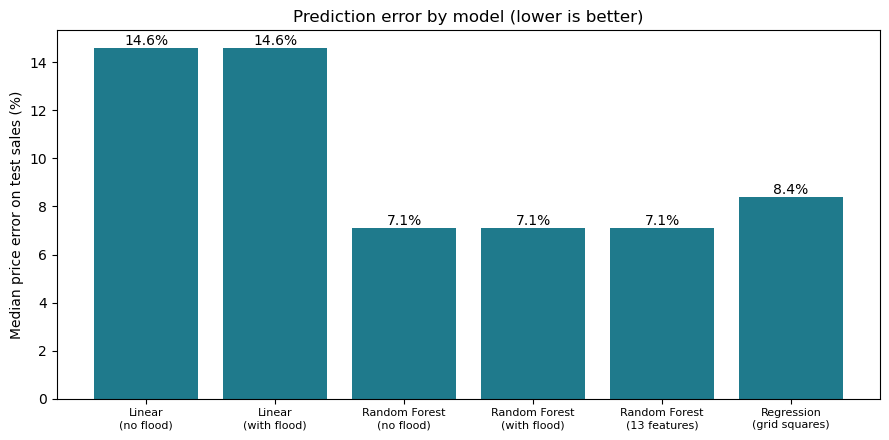

In [3]:
short = ["Linear\n(no flood)", "Linear\n(with flood)", "Random Forest\n(no flood)",
         "Random Forest\n(with flood)", "Random Forest\n(13 features)", "Regression\n(grid squares)"]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(short, models["median_error_pct"], color="#1f7a8c")
ax.bar_label(bars, fmt="%.1f%%")
ax.set_ylabel("Median price error on test sales (%)")
ax.set_title("Prediction error by model (lower is better)")
plt.xticks(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "model_comparison.png", dpi=150)
plt.show()

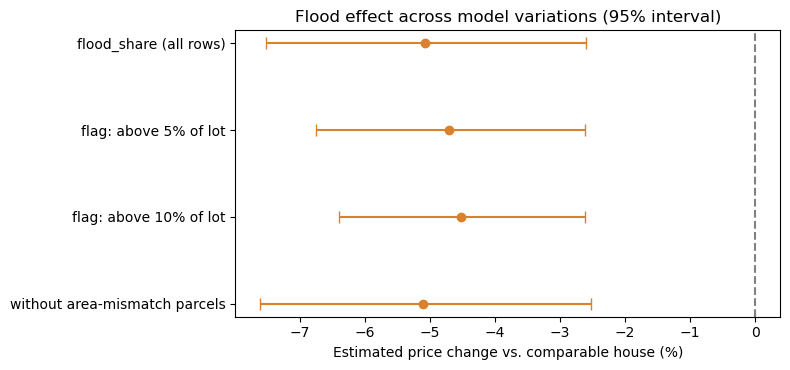

In [4]:
pct = lambda x: (np.exp(x) - 1) * 100
est = pct(flood["coefficient"]); lo = pct(flood["ci_low"]); hi = pct(flood["ci_high"])

fig, ax = plt.subplots(figsize=(8, 3.8))
y = range(len(flood))
ax.errorbar(est, y, xerr=[est - lo, hi - est], fmt="o", color="#d9822b", capsize=4)
ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks(list(y)); ax.set_yticklabels(flood["version"])
ax.invert_yaxis()
ax.set_xlabel("Estimated price change vs. comparable house (%)")
ax.set_title("Flood effect across model variations (95% interval)")
plt.tight_layout()
plt.savefig(RESULTS / "flood_effect.png", dpi=150)
plt.show()

In [5]:
import pandas, numpy, geopandas, shapely, sklearn, statsmodels, matplotlib
for m in [pandas, numpy, geopandas, shapely, sklearn, statsmodels, matplotlib]:
    print(m.__name__, m.__version__)

pandas 2.3.3
numpy 2.3.5
geopandas 1.2.0
shapely 2.2.0
sklearn 1.7.2
statsmodels 0.14.5
matplotlib 3.10.6
